# NeumonAI – Fase 2: Solución con CNN (Redes Neuronales)


In [ ]:
# 0. Librerías y configuración global
import os, re, glob, hashlib, itertools, time, shutil, warnings, subprocess
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve, classification_report)
warnings.filterwarnings('ignore'); sns.set_theme(style='whitegrid')

SEED, IMG, BATCH = 42, 150, 32
EPOCHS = 3      # restricción del proyecto (súbelo a 10 si el tiempo lo permite)
N_REPS = 3      # repeticiones por configuración
os.makedirs('evidencias', exist_ok=True)

def guardar(nombre):
    plt.savefig(f'evidencias/{nombre}.png', dpi=150, bbox_inches='tight'); plt.show()

print('GPU:', tf.config.list_physical_devices('GPU') or 'NO DETECTADA (será lento)')

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Modelo de datos

### 1 Descarga del dataset



In [ ]:
!pip install -q kaggle
!mkdir -p ~/.kaggle
!mv kaggle.json ~/.kaggle/ 2>/dev/null || true
!chmod 600 ~/.kaggle/kaggle.json 2>/dev/null || true
import os
if not os.path.exists('chest_xray_pneumonia'):
    !kaggle datasets download -d paultimothymooney/chest-xray-pneumonia
    !unzip -o -q chest-xray-pneumonia.zip -d chest_xray_pneumonia
print('Dataset listo.')

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
100% 2.29G/2.29G [02:19<00:00, 17.7MB/s]

Dataset listo.


### 2 Inventario original
Contamos imágenes por partición y clase.

clase,NORMAL,PNEUMONIA,All,% neumonía
split,,,,
test,234,390,624,62.5
train,1341,3875,5216,74.3
val,8,8,16,50.0
All,1583,4273,5856,73.0


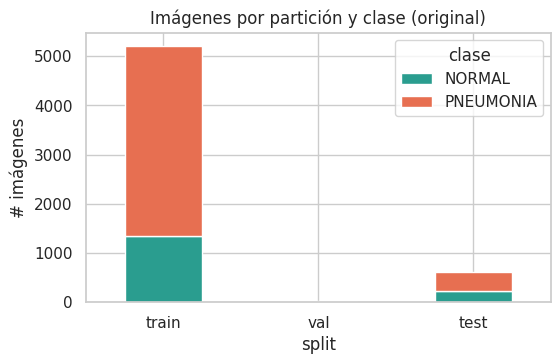

In [ ]:
BASE = 'chest_xray_pneumonia/chest_xray'
rows = [dict(path=p, split=s, clase=c)
        for s in ['train','val','test'] for c in ['NORMAL','PNEUMONIA']
        for p in glob.glob(f'{BASE}/{s}/{c}/*.jp*g')]
df = pd.DataFrame(rows); df['y'] = (df.clase == 'PNEUMONIA').astype(int)

tabla_orig = pd.crosstab(df.split, df.clase, margins=True)
tabla_orig['% neumonía'] = (100 * tabla_orig.PNEUMONIA / tabla_orig.All).round(1)
display(tabla_orig)
tabla_orig.to_csv('evidencias/tabla_inventario_original.csv')

pd.crosstab(df.split, df.clase).loc[['train','val','test']].plot(kind='bar', stacked=True, figsize=(6,3.5), color=['#2a9d8f','#e76f51'])
plt.title('Imágenes por partición y clase (original)'); plt.xticks(rotation=0); plt.ylabel('# imágenes')
guardar('A2_inventario_original')

### 3 Muestras y calidad de los archivos
Revisamos: archivos corruptos, tamaños, canales y duplicados exactos.

  0%|          | 0/5856 [00:00<?, ?it/s]

Archivos corruptos: 0
Modos de color: {'L': 5573, 'RGB': 283}
Duplicados exactos: 32


w                                                        \
            count    mean    std    min     25%     50%     75%     max   
clase                                                                     
NORMAL     1583.0  1686.0  305.0  912.0  1472.0  1654.0  1848.0  2916.0   
PNEUMONIA  4273.0  1195.0  285.0  384.0  1000.0  1160.0  1360.0  2772.0   

                h                                                        
            count    mean    std    min     25%     50%     75%     max  
clase                                                                    
NORMAL     1583.0  1379.0  343.0  496.0  1140.0  1323.0  1554.0  2713.0  
PNEUMONIA  4273.0   820.0  271.0  127.0   640.0   776.0   960.0  2304.0

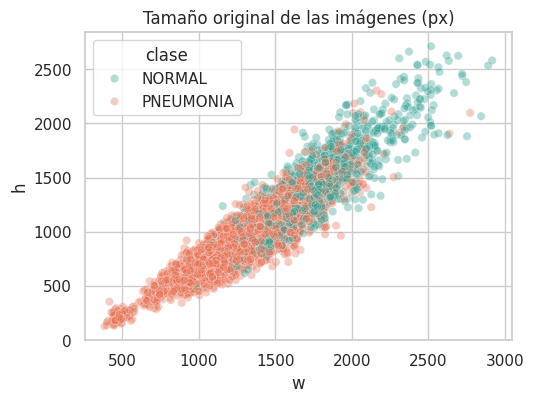

In [ ]:
def info(p):
    try:
        with Image.open(p) as im:
            w, h, modo = im.size[0], im.size[1], im.mode
            im.verify()
        return w, h, modo, hashlib.md5(open(p,'rb').read()).hexdigest(), True
    except Exception:
        return None, None, None, None, False

with ThreadPoolExecutor(8) as ex: out = list(tqdm(ex.map(info, df.path), total=len(df)))
df[['w','h','modo','md5','ok']] = pd.DataFrame(out, index=df.index)

print('Archivos corruptos:', (df.ok == False).sum())
print('Modos de color:', df.modo.value_counts().to_dict())
print('Duplicados exactos:', df.md5.duplicated().sum())
display(df.groupby('clase')[['w','h']].describe().round(0))

plt.figure(figsize=(5.5,4))
sns.scatterplot(data=df, x='w', y='h', hue='clase', alpha=.35, palette=['#2a9d8f','#e76f51'])
plt.title('Tamaño original de las imágenes (px)'); guardar('A3_tamanos')

### 4 Limpieza
1. Eliminar archivos corruptos.
2. Eliminar imágenes de train/val cuyo contenido **también está en test** (fuga de datos).
3. Eliminar duplicados exactos restantes.

In [ ]:
n0 = len(df)
df = df[df.ok == True]
n_corr = n0 - len(df)
test_hashes = set(df[df.split=='test'].md5)
mask_fuga = (df.split != 'test') & df.md5.isin(test_hashes)
n_fuga = mask_fuga.sum(); df = df[~mask_fuga]
n_dup = df.md5.duplicated().sum(); df = df.drop_duplicates('md5').reset_index(drop=True)

limpieza = pd.DataFrame({'Paso': ['Corruptos','Fuga train/val→test','Duplicados exactos','Imágenes finales'],
                         'Imágenes': [n_corr, n_fuga, n_dup, len(df)]})
display(limpieza); limpieza.to_csv('evidencias/tabla_limpieza.csv', index=False)

,Paso,Imágenes
0,Corruptos,0
1,Fuga train/val→test,0
2,Duplicados exactos,32
3,Imágenes finales,5824


### 5 Nueva partición train / val / test
- **Test** se deja intacto (624 imágenes originales)
- Se **junta train + val** y se re-divide 80/20.

clase,NORMAL,PNEUMONIA,All,% neumonía
particion,,,,
train,1068,3100,4168,74.4
val,280,758,1038,73.0
test,231,387,618,62.6
All,1579,4245,5824,72.9


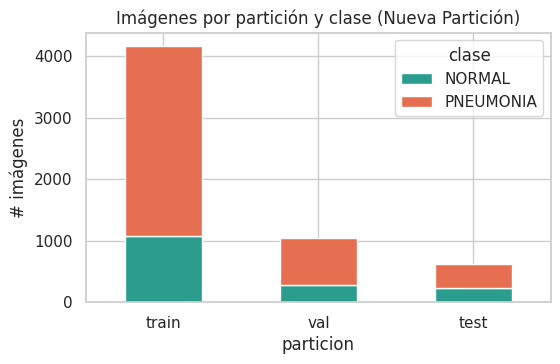

In [ ]:
def grupo(r):
    n = os.path.basename(r.path)
    m = re.search(r'person(\d+)', n) or re.search(r'IM-(\d+)', n)
    return f'{r.clase}_{m.group(1)}' if m else n
df['grupo'] = df.apply(grupo, axis=1)

dev = df[df.split != 'test'].reset_index(drop=True)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
tr_idx, va_idx = next(sgkf.split(dev, dev.y, groups=dev.grupo))
dev['particion'] = 'train'; dev.loc[va_idx, 'particion'] = 'val'
te = df[df.split == 'test'].copy(); te['particion'] = 'test'
data = pd.concat([dev, te]).reset_index(drop=True)

assert set(dev[dev.particion=='train'].grupo).isdisjoint(dev[dev.particion=='val'].grupo)
tabla_final = pd.crosstab(data.particion, data.clase, margins=True).loc[['train','val','test','All']]
tabla_final['% neumonía'] = (100 * tabla_final.PNEUMONIA / tabla_final.All).round(1)
display(tabla_final); tabla_final.to_csv('evidencias/tabla_particion_final.csv')

# Generación de la gráfica de barras de la nueva partición
pd.crosstab(data.particion, data.clase).loc[['train','val','test']].plot(kind='bar', stacked=True, figsize=(6,3.5), color=['#2a9d8f','#e76f51'])
plt.title('Imágenes por partición y clase (Nueva Partición)')
plt.xticks(rotation=0)
plt.ylabel('# imágenes')
guardar('A5_inventario_final')

### 6 Preprocesamiento y mejoras
- Escala de grises (1 canal) y **redimensión a 150×150**.
- Normalización 0–1 (se hace dentro del modelo).
- **Pesos de clase** para compensar el desbalance.
- **Aumento de datos** (rotación, zoom, traslación y contraste leves).

  0%|          | 0/5824 [00:00<?, ?it/s]

Formas: (4168, 150, 150, 1) (1038, 150, 150, 1) (618, 150, 150, 1)
Pesos de clase: {0: np.float64(1.95), 1: np.float64(0.67)}


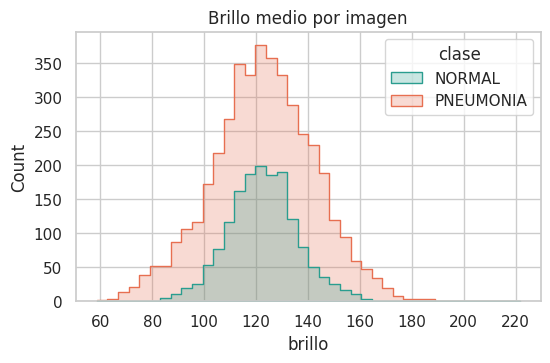

In [ ]:
def cargar(p): return np.asarray(Image.open(p).convert('L').resize((IMG, IMG), Image.BILINEAR), dtype=np.uint8)
with ThreadPoolExecutor(8) as ex: imgs = list(tqdm(ex.map(cargar, data.path), total=len(data)))
X = np.stack(imgs)[..., None]; y = data.y.values
m_tr, m_va, m_te = [(data.particion == s).values for s in ['train','val','test']]
Xtr, ytr, Xva, yva, Xte, yte = X[m_tr], y[m_tr], X[m_va], y[m_va], X[m_te], y[m_te]
print('Formas:', Xtr.shape, Xva.shape, Xte.shape)

n0, n1 = (ytr==0).sum(), (ytr==1).sum()
CW = {0: len(ytr)/(2*n0), 1: len(ytr)/(2*n1)}
print('Pesos de clase:', {k: round(v,2) for k, v in CW.items()})

data['brillo'] = X.mean(axis=(1,2,3))
plt.figure(figsize=(6,3.5)); sns.histplot(data=data, x='brillo', hue='clase', bins=40, element='step', palette=['#2a9d8f','#e76f51'])
plt.title('Brillo medio por imagen'); guardar('A6_brillo')

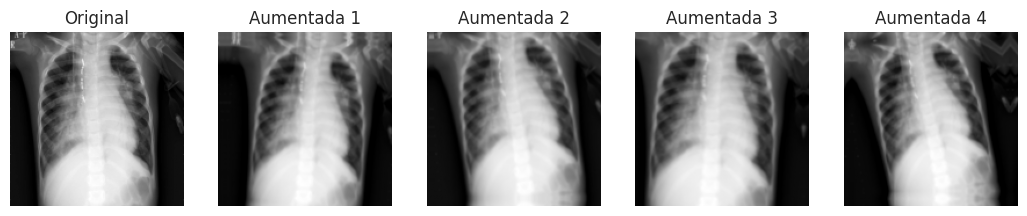

In [ ]:
def augment_layers():
    L = tf.keras.layers
    return tf.keras.Sequential([L.RandomRotation(0.05), L.RandomZoom(0.1),
                                L.RandomTranslation(0.05, 0.05), L.RandomContrast(0.1)], name='aumento')

idx = np.where(ytr == 1)[0][0]; img = Xtr[idx:idx+1].astype('float32') / 255
fig, axs = plt.subplots(1, 5, figsize=(13, 3))
axs[0].imshow(img[0,...,0], cmap='gray'); axs[0].set_title('Original')
aug_demo = augment_layers()
for k in range(1, 5):
    axs[k].imshow(aug_demo(img, training=True)[0,...,0], cmap='gray'); axs[k].set_title(f'Aumentada {k}')
for a in axs: a.axis('off')
guardar('A6_aumento_datos')

## Modelo CNN
Arquitectura base (misma del baseline): bloques *Conv2D + MaxPooling* → *Flatten* → *Dense(128)* → *Dropout* → *Dense(1, sigmoide)*.
Los **hiperparámetros que se van a experimentar** son: aumento de datos, learning rate, dropout y número de bloques convolucionales (2 o 3, con 32/64/128 filtros).

In [ ]:
def build(aug, lr, dropout, bloques):
    L = tf.keras.layers
    capas = [L.Input((IMG, IMG, 1)), L.Rescaling(1/255)]
    if aug: capas.append(augment_layers())           # solo actúa en entrenamiento
    for i in range(bloques):
        capas += [L.Conv2D(32 * 2**i, 3, activation='relu'), L.MaxPooling2D(2)]
    capas += [L.Flatten(), L.Dense(128, activation='relu'), L.Dropout(dropout), L.Dense(1, activation='sigmoid')]
    m = tf.keras.Sequential(capas)
    m.compile(optimizer=tf.keras.optimizers.Adam(lr), loss='binary_crossentropy',
              metrics=['accuracy', tf.keras.metrics.Recall(name='recall')])
    return m

build(True, 1e-3, 0.5, 3).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 150, 150, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aumento (Sequential)            │ (None, 150, 150, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,827,905 (18.42 MB)

 Trainable params: 4,827,905 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

## Protocolo experimental


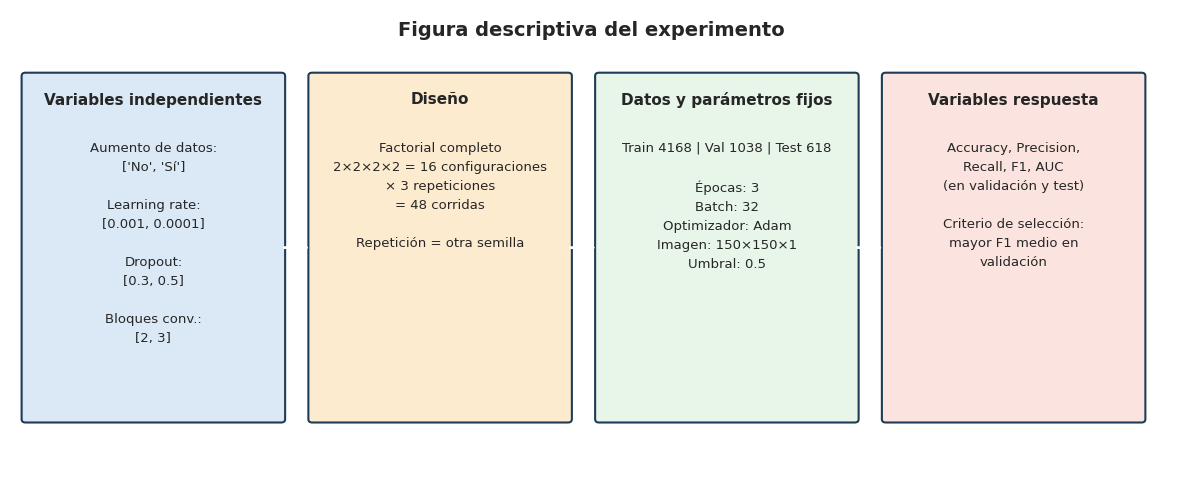

In [ ]:
FACTORES = {'aug': ['No','Sí'], 'lr': [1e-3, 1e-4], 'dropout': [0.3, 0.5], 'bloques': [2, 3]}
ETIQ = {'aug':'Aumento de datos','lr':'Learning rate','dropout':'Dropout','bloques':'Bloques conv.'}
CONFIGS = list(itertools.product(*FACTORES.values()))
FIJOS = {'Épocas': EPOCHS, 'Batch': BATCH, 'Optimizador': 'Adam', 'Imagen': '150×150×1', 'Umbral': 0.5}
N_RUNS = len(CONFIGS) * N_REPS

from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(15, 6)); ax.set_xlim(0, 15); ax.set_ylim(0, 7); ax.axis('off')
def caja(x, titulo, cuerpo, color, w=3.3):
    ax.add_patch(FancyBboxPatch((x, 0.8), w, 5.2, boxstyle='round,pad=0.05', fc=color, ec='#1f3b57', lw=1.5))
    ax.text(x + w/2, 5.75, titulo, ha='center', va='top', fontweight='bold', fontsize=11)
    ax.text(x + w/2, 5.0, cuerpo, ha='center', va='top', fontsize=9.5, linespacing=1.6)
def flecha(x): ax.annotate('', xy=(x+0.4, 3.4), xytext=(x, 3.4), arrowprops=dict(arrowstyle='->', lw=2))

caja(0.2, 'Variables independientes', '\n\n'.join(f'{ETIQ[k]}:\n{v}' for k, v in FACTORES.items()), '#dbe9f6')
caja(3.9, 'Diseño', f'Factorial completo\n2×2×2×2 = {len(CONFIGS)} configuraciones\n× {N_REPS} repeticiones\n= {N_RUNS} corridas\n\nRepetición = otra semilla', '#fdebd0')
caja(7.6, 'Datos y parámetros fijos', f'Train {len(ytr)} | Val {len(yva)} | Test {len(yte)}\n\n' + '\n'.join(f'{k}: {v}' for k, v in FIJOS.items()), '#e8f6e9')
caja(11.3, 'Variables respuesta', 'Accuracy, Precision,\nRecall, F1, AUC\n(en validación y test)\n\nCriterio de selección:\nmayor F1 medio en\nvalidación', '#fbe3e0')
for x in (3.5, 7.2, 10.9): flecha(x)
ax.text(7.5, 6.6, 'Figura descriptiva del experimento', ha='center', fontsize=14, fontweight='bold')
guardar('C_diseno_experimental')

### Ejecución del experimento
Para cada corrida: entrenar → evaluar en validación y test → guardar métricas.

In [ ]:
def ds(Xa, ya, train=False):
    d = tf.data.Dataset.from_tensor_slices((Xa, ya.astype('float32')))
    if train: d = d.shuffle(len(Xa), seed=SEED)
    return d.batch(BATCH).prefetch(tf.data.AUTOTUNE)
ds_tr, ds_va = ds(Xtr, ytr, True), ds(Xva, yva)

def metricas(m, Xa, ya):
    p = m.predict(Xa, batch_size=128, verbose=0).ravel(); yh = (p >= 0.5).astype(int)
    return dict(acc=accuracy_score(ya, yh), prec=precision_score(ya, yh, zero_division=0),
                recall=recall_score(ya, yh), f1=f1_score(ya, yh), auc=roc_auc_score(ya, p)), p

def entrenar(aug, lr, dropout, bloques, seed):
    tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(seed)
    m = build(aug == 'Sí', lr, dropout, bloques)
    h = m.fit(ds_tr, epochs=EPOCHS, validation_data=ds_va, class_weight=CW, verbose=0)
    return m, h

filas = []; t0 = time.time()
for (aug, lr, do, bl), rep in tqdm(list(itertools.product(CONFIGS, range(N_REPS))), desc='Corridas'):
    m, h = entrenar(aug, lr, do, bl, SEED + rep)
    mv, _ = metricas(m, Xva, yva); mt, _ = metricas(m, Xte, yte)
    filas.append(dict(aug=aug, lr=lr, dropout=do, bloques=bl, rep=rep,
                      **{f'val_{k}': v for k, v in mv.items()}, **{f'test_{k}': v for k, v in mt.items()}))
    pd.DataFrame(filas).to_csv('evidencias/resultados_crudos.csv', index=False)
print(f'Listo: {len(filas)} corridas en {(time.time()-t0)/60:.1f} min')

Corridas:   0%|          | 0/48 [00:00<?, ?it/s]

Listo: 48 corridas en 13.2 min


## Resultados y análisis

### 1 Ranking de configuraciones
Tabla con media ± desviación (3 repeticiones). Se ordena por **F1 en validación**. Se incluye el **baseline** (la CNN original del notebook inicial) para comparar.

In [ ]:
res = pd.DataFrame(filas)
res['config'] = res.apply(lambda r: f'aug={r.aug} | lr={r.lr:g} | do={r.dropout} | bl={r.bloques}', axis=1)
BASELINE = 'aug=No | lr=0.001 | do=0.5 | bl=2'

cols = ['val_f1', 'val_recall', 'test_f1', 'test_recall', 'test_prec', 'test_acc', 'test_auc']
g = res.groupby('config')[cols].agg(['mean', 'std'])
orden = g[('val_f1', 'mean')].sort_values(ascending=False).index
tabla = pd.DataFrame({c: g[c]['mean'].round(3).astype(str) + ' ± ' + g[c]['std'].round(3).astype(str) for c in cols}).loc[orden]
tabla.insert(0, 'rank', range(1, len(tabla) + 1))
tabla.to_csv('evidencias/tabla_configuraciones.csv')

MEJOR = orden[0]
print('Top 5 configuraciones (por F1 en validación):'); display(tabla.head(5))
print('Baseline:'); display(tabla.loc[[BASELINE]])

Top 5 configuraciones (por F1 en validación):


,rank,val_f1,val_recall,test_f1,test_recall,test_prec,test_acc,test_auc
config,,,,,,,,
aug=No | lr=0.001 | do=0.3 | bl=2,1,0.974 ± 0.006,0.969 ± 0.019,0.845 ± 0.018,0.988 ± 0.01,0.739 ± 0.034,0.772 ± 0.034,0.91 ± 0.021
aug=No | lr=0.001 | do=0.5 | bl=2,2,0.969 ± 0.007,0.951 ± 0.016,0.858 ± 0.015,0.981 ± 0.003,0.762 ± 0.026,0.796 ± 0.026,0.905 ± 0.017
aug=No | lr=0.001 | do=0.3 | bl=3,3,0.969 ± 0.012,0.965 ± 0.035,0.848 ± 0.029,0.989 ± 0.013,0.743 ± 0.053,0.776 ± 0.052,0.906 ± 0.022
aug=No | lr=0.0001 | do=0.3 | bl=2,4,0.968 ± 0.003,0.964 ± 0.018,0.859 ± 0.024,0.98 ± 0.017,0.765 ± 0.048,0.797 ± 0.045,0.94 ± 0.004
aug=No | lr=0.0001 | do=0.3 | bl=3,5,0.968 ± 0.004,0.969 ± 0.016,0.849 ± 0.017,0.984 ± 0.012,0.748 ± 0.034,0.781 ± 0.032,0.929 ± 0.005


Baseline:


,rank,val_f1,val_recall,test_f1,test_recall,test_prec,test_acc,test_auc
config,,,,,,,,
aug=No | lr=0.001 | do=0.5 | bl=2,2,0.969 ± 0.007,0.951 ± 0.016,0.858 ± 0.015,0.981 ± 0.003,0.762 ± 0.026,0.796 ± 0.026,0.905 ± 0.017


### 2 Efecto de cada variable independiente
Promedio de F1 y Recall (validación) en cada nivel. Barras de error = desviación estándar.

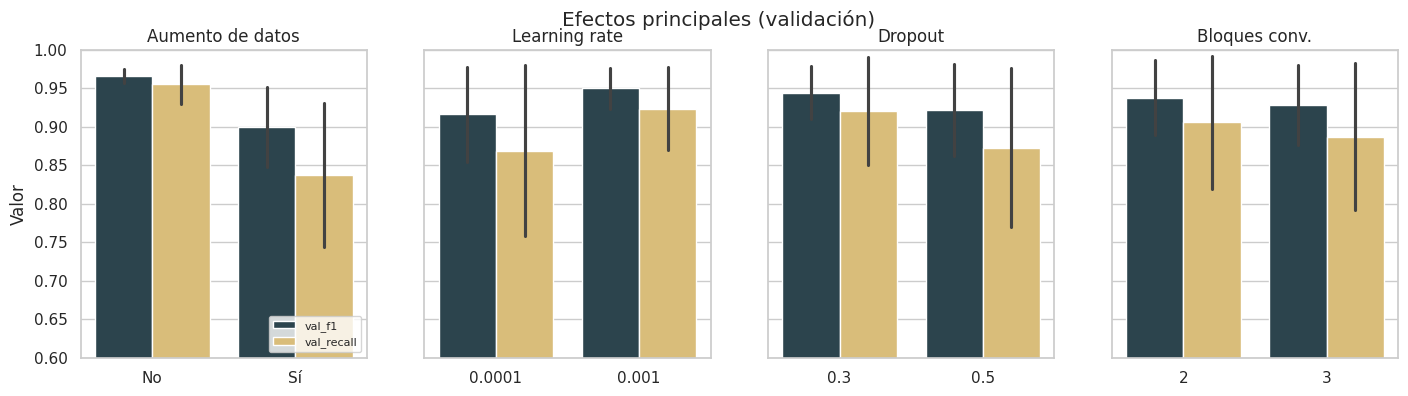

val_f1  val_recall  test_f1  test_recall
Aumento de datos No       0.966       0.955    0.859        0.979
                 Sí       0.900       0.837    0.870        0.871
Learning rate    0.0001   0.916       0.869    0.860        0.891
                 0.001    0.950       0.924    0.869        0.958
Dropout          0.3      0.944       0.920    0.866        0.948
                 0.5      0.922       0.873    0.863        0.902
Bloques conv.    2        0.938       0.906    0.863        0.930
                 3        0.928       0.887    0.866        0.920

In [ ]:
FACT = list(FACTORES)
fig, axs = plt.subplots(1, 4, figsize=(17, 4), sharey=True)
for ax, f in zip(axs, FACT):
    d = res.melt(id_vars=[f], value_vars=['val_f1', 'val_recall'], var_name='métrica', value_name='valor')
    sns.barplot(data=d, x=f, y='valor', hue='métrica', errorbar='sd', ax=ax, palette=['#264653', '#e9c46a'])
    ax.set_title(ETIQ[f]); ax.set_xlabel(''); ax.legend(loc='lower right', fontsize=8) if f == 'aug' else ax.legend_.remove()
axs[0].set_ylabel('Valor'); axs[0].set_ylim(0.6, 1.0)
plt.suptitle('Efectos principales (validación)'); guardar('D2_efectos_principales')

efectos = pd.concat({ETIQ[f]: res.groupby(f)[['val_f1','val_recall','test_f1','test_recall']].mean().round(3) for f in FACT})
display(efectos); efectos.to_csv('evidencias/tabla_efectos.csv')

### 3 Generalización y compromiso Precision–Recall
Izquierda: ¿lo que se ve bueno en validación se mantiene en test? Derecha: Recall vs Precision por configuración (nos importa el **Recall** para evitar falsos negativos).

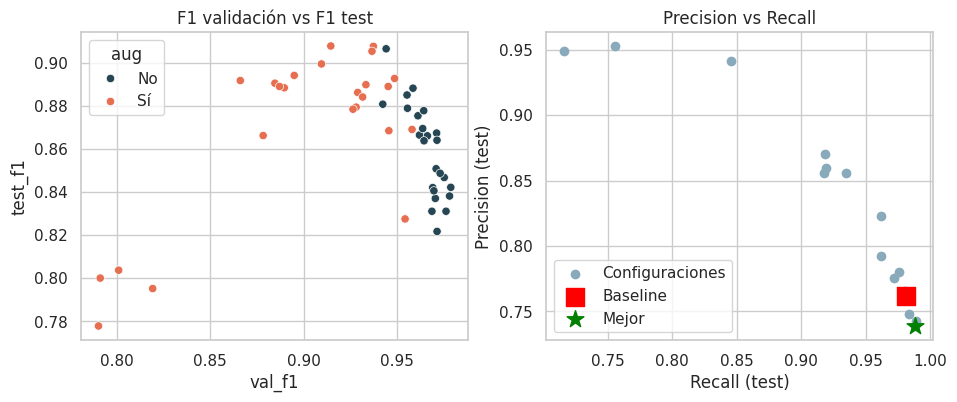

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
sns.scatterplot(data=res, x='val_f1', y='test_f1', hue='aug', ax=axs[0], palette=['#264653', '#e76f51'])

# Se eliminó la línea: axs[0].plot([0.7, 1], [0.7, 1], 'k--', lw=1);
axs[0].set_title('F1 validación vs F1 test')

mc = res.groupby('config')[['test_prec', 'test_recall']].mean()
axs[1].scatter(mc.test_recall, mc.test_prec, c='#8ab', label='Configuraciones')
for nombre, col, mk in [(BASELINE, 'red', 's'), (MEJOR, 'green', '*')]:
    axs[1].scatter(mc.loc[nombre, 'test_recall'], mc.loc[nombre, 'test_prec'], c=col, marker=mk, s=160,
                   label='Baseline' if nombre == BASELINE else 'Mejor')
axs[1].set_xlabel('Recall (test)'); axs[1].set_ylabel('Precision (test)');
# Leyenda reubicada a la esquina inferior izquierda
axs[1].legend(loc='lower left');
axs[1].set_title('Precision vs Recall')
guardar('D4_generalizacion')

### 4 Evaluación final de la mejor configuración
Se re-entrena la mejor configuración y se evalúa en test: curvas de aprendizaje, matriz de confusión y ROC.

Mejor configuración: aug=No | lr=0.001 | do=0.3 | bl=2


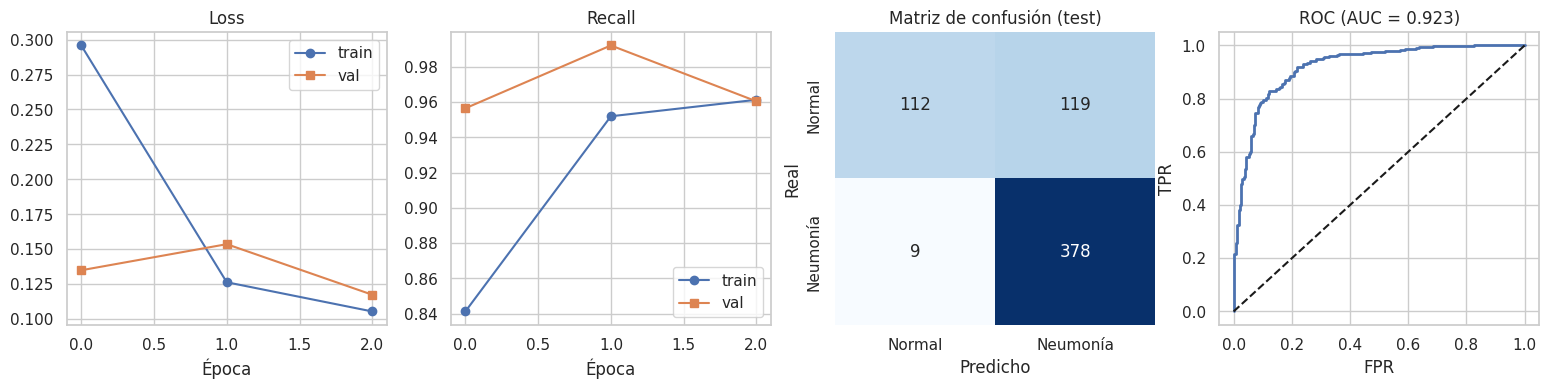

              precision    recall  f1-score   support

      Normal      0.926     0.485     0.636       231
    Neumonía      0.761     0.977     0.855       387

    accuracy                          0.793       618
   macro avg      0.843     0.731     0.746       618
weighted avg      0.822     0.793     0.773       618



In [ ]:
mejor = res[res.config == MEJOR].iloc[0]
mb, hb = entrenar(mejor.aug, float(mejor.lr), float(mejor.dropout), int(mejor.bloques), SEED)
mt, p = metricas(mb, Xte, yte); yh = (p >= 0.5).astype(int)
print('Mejor configuración:', MEJOR)

fig, axs = plt.subplots(1, 4, figsize=(19, 3.8))
for ax, k, t in [(axs[0], 'loss', 'Loss'), (axs[1], 'recall', 'Recall')]:
    ax.plot(hb.history[k], 'o-', label='train'); ax.plot(hb.history['val_' + k], 's-', label='val')
    ax.set_title(t); ax.set_xlabel('Época'); ax.legend()
sns.heatmap(confusion_matrix(yte, yh), annot=True, fmt='d', cmap='Blues', cbar=False, ax=axs[2],
            xticklabels=['Normal', 'Neumonía'], yticklabels=['Normal', 'Neumonía'])
axs[2].set_title('Matriz de confusión (test)'); axs[2].set_xlabel('Predicho'); axs[2].set_ylabel('Real')
fpr, tpr, _ = roc_curve(yte, p); axs[3].plot(fpr, tpr, lw=2); axs[3].plot([0, 1], [0, 1], 'k--')
axs[3].set_title(f'ROC (AUC = {mt["auc"]:.3f})'); axs[3].set_xlabel('FPR'); axs[3].set_ylabel('TPR')
guardar('D5_evaluacion_mejor_modelo')
print(classification_report(yte, yh, target_names=['Normal', 'Neumonía'], digits=3))

Evaluando Modelo Baseline...


Evaluando Mejor Configuración...



--- MÉTRICAS EN EL CONJUNTO DE PRUEBA (TEST) ---
BASELINE (aug=No | lr=0.001 | do=0.5 | bl=2):
  F1: 0.858 | Recall: 0.969 | Precision: 0.770 | Exactitud: 0.799 | AUC: 0.918

MEJOR MODELO (aug=No | lr=0.001 | do=0.3 | bl=2):
  F1: 0.862 | Recall: 0.987 | Precision: 0.766 | Exactitud: 0.803 | AUC: 0.928

-> Mejora clínica en Recall: +0.018



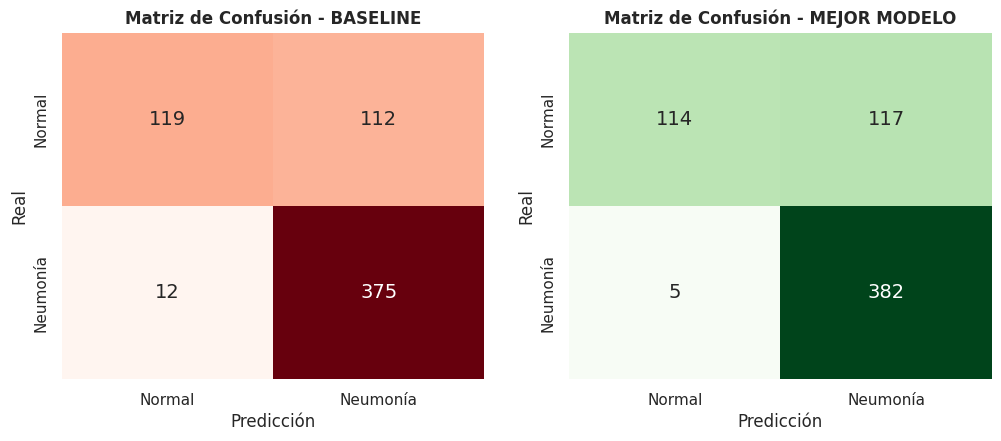

In [ ]:
# Obtener los hiperparámetros de ambas configuraciones
mejor = res[res.config == MEJOR].iloc[0]
baseline = res[res.config == BASELINE].iloc[0]

# Entrenar ambos modelos con la misma semilla para una comparación justa
print("Evaluando Modelo Baseline...")
m_base, _ = entrenar(baseline.aug, float(baseline.lr), float(baseline.dropout), int(baseline.bloques), SEED)
mt_base, p_base = metricas(m_base, Xte, yte)
yh_base = (p_base >= 0.5).astype(int)

print("Evaluando Mejor Configuración...")
m_mejor, _ = entrenar(mejor.aug, float(mejor.lr), float(mejor.dropout), int(mejor.bloques), SEED)
mt_mejor, p_mejor = metricas(m_mejor, Xte, yte)
yh_mejor = (p_mejor >= 0.5).astype(int)

# Imprimir las métricas comparativas
print('\n--- MÉTRICAS EN EL CONJUNTO DE PRUEBA (TEST) ---')
print(f'BASELINE ({BASELINE}):')
print(f'  F1: {mt_base["f1"]:.3f} | Recall: {mt_base["recall"]:.3f} | Precision: {mt_base["prec"]:.3f} | Exactitud: {mt_base["acc"]:.3f} | AUC: {mt_base["auc"]:.3f}')

print(f'\nMEJOR MODELO ({MEJOR}):')
print(f'  F1: {mt_mejor["f1"]:.3f} | Recall: {mt_mejor["recall"]:.3f} | Precision: {mt_mejor["prec"]:.3f} | Exactitud: {mt_mejor["acc"]:.3f} | AUC: {mt_mejor["auc"]:.3f}')

print(f'\n-> Mejora clínica en Recall: {mt_mejor["recall"] - mt_base["recall"]:+.3f}\n')

# Dibujar las matrices de confusión lado a lado
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))

sns.heatmap(confusion_matrix(yte, yh_base), annot=True, fmt='d', cmap='Reds', cbar=False, ax=axs[0],
            xticklabels=['Normal', 'Neumonía'], yticklabels=['Normal', 'Neumonía'], annot_kws={"size": 14})
axs[0].set_title('Matriz de Confusión - BASELINE', fontsize=12, fontweight='bold')
axs[0].set_xlabel('Predicción')
axs[0].set_ylabel('Real')

sns.heatmap(confusion_matrix(yte, yh_mejor), annot=True, fmt='d', cmap='Greens', cbar=False, ax=axs[1],
            xticklabels=['Normal', 'Neumonía'], yticklabels=['Normal', 'Neumonía'], annot_kws={"size": 14})
axs[1].set_title('Matriz de Confusión - MEJOR MODELO', fontsize=12, fontweight='bold')
axs[1].set_xlabel('Predicción')
axs[1].set_ylabel('Real')

# Mostrar directamente en pantalla sin guardar nada
plt.show()

# Algoritmos genéticos (AG)

### Búsqueda Estructural (ACO) e Hiperparámetros (GA) sobre el Dataset Completo

En esta celda se ejecutan de manera consecutiva los dos algoritmos de optimización previa sobre el 100% de los datos de entrenamiento (`Xtr`, `ytr`) y validación (`Xva`, `yva`):
1. **ACO (*DeepSwarm* – Ref. 1):** Explora el grafo DAG para determinar la mejor combinación de filtros, tamaños de kernel ($3\times 3$ vs. $5\times 5$) y tipos de *pooling* (`MaxPooling2D` vs. `AveragePooling2D`).
2. **GA (*EvoCNN* – Refs. 2, 3):** Evoluciona los hiperparámetros de entrenamiento (`lr`, `dropout`, `dense_units`) y los parámetros estadísticos del inicializador gaussiano de pesos ($\mu, \sigma$).

Al finalizar, imprime la topología y los hiperparámetros óptimos que se utilizarán en el protocolo experimental.

In [ ]:
# Ejecutamos las metaheurísticas (ACO y GA) directamente sobre todo el dataset (Xtr, ytr, Xva, yva)
# utilizando las clases ya definidas que referencian los datos globales.

print(">>> Iniciando Búsqueda ACO (Full Data)...")
aco = DeepSwarmACO(n_ants=3, n_iters=5) # Parámetros mantenidos conservadores para viabilidad en Colab, pero con datos completos
mejor_arch_aco, curva_aco = aco.optimizar(hp_fijos=BASE_HP)

print("\n>>> Iniciando Búsqueda GA (Full Data)...")
ga = EvoCNNGeneticAlgorithm(pop_size=3, n_gens=5)
mejor_hp_ga, curva_ga = ga.optimizar(arch_fija=mejor_arch_aco)

print("\n=========================================")
print("Resultados Finales de Búsqueda Metaheurística:")
print("Topología Óptima (ACO):", mejor_arch_aco)
print("Hiperparámetros Óptimos (GA):", mejor_hp_ga)
print("=========================================")

>>> Iniciando Búsqueda ACO (Full Data)...
>>> [ACO - DeepSwarm Ref 1] Buscando topología sobre Xtr COMPLETO (4168 imágenes)...
  [ACO Iter 1/5] Mejor Fitness Val: 0.9370 | Topología: {'f1': 16, 'k1': 5, 'p1': 'max', 'f2': 64, 'k2': 3, 'p2': 'max', 'use_b3': 0, 'f3': 32, 'k3': 5, 'p3': 'max'}
  [ACO Iter 2/5] Mejor Fitness Val: 0.9370 | Topología: {'f1': 16, 'k1': 5, 'p1': 'max', 'f2': 64, 'k2': 3, 'p2': 'max', 'use_b3': 0, 'f3': 32, 'k3': 5, 'p3': 'max'}
  [ACO Iter 3/5] Mejor Fitness Val: 0.9370 | Topología: {'f1': 16, 'k1': 5, 'p1': 'max', 'f2': 64, 'k2': 3, 'p2': 'max', 'use_b3': 0, 'f3': 32, 'k3': 5, 'p3': 'max'}
  [ACO Iter 4/5] Mejor Fitness Val: 0.9400 | Topología: {'f1': 16, 'k1': 5, 'p1': 'max', 'f2': 64, 'k2': 3, 'p2': 'max', 'use_b3': 0, 'f3': 32, 'k3': 3, 'p3': 'max'}
  [ACO Iter 5/5] Mejor Fitness Val: 0.9400 | Topología: {'f1': 16, 'k1': 5, 'p1': 'max', 'f2': 64, 'k2': 3, 'p2': 'max', 'use_b3': 0, 'f3': 32, 'k3': 3, 'p3': 'max'}

>>> Iniciando Búsqueda GA (Full Data)...



### Ejecución del Protocolo Experimental Completo (Tratamientos E0 a E5)

Esta celda constituye el núcleo de la experimentación. Implementa los 6 tratamientos definidos para contrastar el impacto de los algoritmos:
* **E0:** Baseline original.
* **E1:** Solo ACO (optimización topológica).
* **E2:** Solo GA (optimización de hiperparámetros e inicialización).
* **E3:** PSO Naive (demuestra empíricamente el caso que **perjudica** al modelo al optimizar pesos sin restricciones).
* **E4:** PSO ZooCNN (aplica *Warm-Start* y factor de inercia decreciente para demostrar el caso que **beneficia** el rendimiento).
* **E5:** Híbrido Completo (ACO + GA + PSO).

Cada tratamiento se ejecuta por triplicado (`N_REPS = 3`) utilizando semillas controladas para garantizar la robustez estadística de los resultados evaluados sobre el conjunto de prueba (`Test`).

In [ ]:
tratamientos = [
    ('E0_Baseline_CNN', BASE_ARCH, BASE_HP, 'none'),
    ('E1_Solo_ACO', mejor_arch_aco, BASE_HP, 'none'),
    ('E2_Solo_GA', BASE_ARCH, mejor_hp_ga, 'none'),
    ('E3_Solo_PSO_Naive', BASE_ARCH, BASE_HP, 'naive'),
    ('E4_Solo_PSO_ZooCNN', BASE_ARCH, BASE_HP, 'zoocnn_pso'),
    ('E5_Hibrido_ACO_GA_PSO', mejor_arch_aco, mejor_hp_ga, 'zoocnn_pso')
]

resultados_finales = []
probabilidades_test = {}

# Curvas PSO para gráfica
curva_pso_naive = []
curva_pso_zoocnn = []

print(">>> Ejecutando Protocolo Final (Dataset Completo, N_REPS=3)...")
for nombre, arch, hp, pso_mode in tratamientos:
    print(f"\nEvaluando Tratamiento: {nombre}")
    probs_reps = []
    for rep in range(N_REPS):
        seed_rep = SEED + rep * 100
        t_ini = time.time()

        # Construir y entrenar
        modelo = construir_cnn_parametrica(arch=arch, hp=hp, seed=seed_rep)
        modelo.fit(Xtr, ytr, epochs=EPOCHS, batch_size=BATCH, class_weight=CW, verbose=0)

        # Aplicar PSO si aplica
        if pso_mode != 'none':
            pso = ZooCNNParticleSwarm(n_particles=5, n_iters=5, modo=pso_mode)
            modelo, hist_pso = pso.optimizar_pesos_subespacio(modelo, Xva, yva, seed=seed_rep)
            if rep == 0 and pso_mode == 'naive':
                curva_pso_naive = hist_pso
            elif rep == 0 and pso_mode == 'zoocnn_pso':
                curva_pso_zoocnn = hist_pso

        # Evaluar en Test
        probs_test = modelo.predict(Xte, batch_size=BATCH, verbose=0).ravel()
        probs_reps.append(probs_test)
        mets = evaluar_metricas_completas(yte, probs_test)
        t_fin = time.time()

        mets['Tratamiento'] = nombre
        mets['Repeticion'] = rep + 1
        mets['Tiempo_s'] = t_fin - t_ini
        resultados_finales.append(mets)
        print(f"  Rep {rep+1} | F1: {mets['F1']:.4f} | AUC: {mets['AUC']:.4f}")

    probabilidades_test[nombre] = np.mean(probs_reps, axis=0)

df_protocolo = pd.DataFrame(resultados_finales)


>>> Ejecutando Protocolo Final (Dataset Completo, N_REPS=3)...

Evaluando Tratamiento: E0_Baseline_CNN
  Rep 1 | F1: 0.8357 | AUC: 0.8684
  Rep 2 | F1: 0.8618 | AUC: 0.8992
  Rep 3 | F1: 0.8737 | AUC: 0.9319

Evaluando Tratamiento: E1_Solo_ACO
  Rep 1 | F1: 0.8462 | AUC: 0.9078
  Rep 2 | F1: 0.8663 | AUC: 0.9162
  Rep 3 | F1: 0.8409 | AUC: 0.9156

Evaluando Tratamiento: E2_Solo_GA
  Rep 1 | F1: 0.8735 | AUC: 0.9106
  Rep 2 | F1: 0.8734 | AUC: 0.9091
  Rep 3 | F1: 0.8897 | AUC: 0.9190

Evaluando Tratamiento: E3_Solo_PSO_Naive
  Rep 1 | F1: 0.8206 | AUC: 0.8195
  Rep 2 | F1: 0.8387 | AUC: 0.9096
  Rep 3 | F1: 0.8497 | AUC: 0.9040

Evaluando Tratamiento: E4_Solo_PSO_ZooCNN
  Rep 1 | F1: 0.8388 | AUC: 0.8838
  Rep 2 | F1: 0.8425 | AUC: 0.9056
  Rep 3 | F1: 0.8510 | AUC: 0.9130

Evaluando Tratamiento: E5_Hibrido_ACO_GA_PSO
  Rep 1 | F1: 0.8494 | AUC: 0.8804
  Rep 2 | F1: 0.8507 | AUC: 0.8878
  Rep 3 | F1: 0.8588 | AUC: 0.9028


## Generación de Tabla y Gráficas

In [ ]:
# ==============================================================================
# 1. CONSTRUCCIÓN DE LA TABLA RESUMEN OFICIAL (Con desglose de mejoras/empeoramientos)
# ==============================================================================

# Extraer los valores medios del Baseline (E0) para usarlos como punto de referencia comparativo
baseline_row = df_protocolo[df_protocolo['Tratamiento'] == 'E0_Baseline_CNN']

base_metrics = {
    'Accuracy': baseline_row['Accuracy'].mean() * 100,
    'Precision': baseline_row['Precision'].mean() * 100,
    'Sensibilidad': (baseline_row['Sensibilidad (Recall)'].mean() if 'Sensibilidad (Recall)' in baseline_row.columns else baseline_row['Sensibilidad'].mean()) * 100,
    'Especificidad': baseline_row['Especificidad'].mean() * 100,
    'F1': baseline_row['F1'].mean(),
    'AUC': baseline_row['AUC'].mean()
}

filas_resumen = []
for nombre, _, _, _ in tratamientos:
    sub = df_protocolo[df_protocolo['Tratamiento'] == nombre]

    acc_m = sub['Accuracy'].mean() * 100
    prec_m = sub['Precision'].mean() * 100
    sens_m = (sub['Sensibilidad (Recall)'].mean() if 'Sensibilidad (Recall)' in sub.columns else sub['Sensibilidad'].mean()) * 100
    esp_m = sub['Especificidad'].mean() * 100
    f1_m, f1_s = sub['F1'].mean(), sub['F1'].std()
    auc_m, auc_s = sub['AUC'].mean(), sub['AUC'].std()
    t_m = sub['Tiempo_s'].mean()

    # Análisis individualizado de qué métrica mejora o empeora frente al Baseline (E0)
    mejoras = []
    empeoramientos = []

    actual_metrics = {
        'Accuracy': acc_m,
        'Precision': prec_m,
        'Sensibilidad': sens_m,
        'Especificidad': esp_m,
        'F1-Score': f1_m,
        'ROC-AUC': auc_m
    }

    ref_metrics = {
        'Accuracy': base_metrics['Accuracy'],
        'Precision': base_metrics['Precision'],
        'Sensibilidad': base_metrics['Sensibilidad'],
        'Especificidad': base_metrics['Especificidad'],
        'F1-Score': base_metrics['F1'],
        'ROC-AUC': base_metrics['AUC']
    }

    for metrica in actual_metrics:
        val_act = actual_metrics[metrica]
        val_ref = ref_metrics[metrica]

        # Margen de tolerancia de 0.0005 para evitar falsos cambios por decimales flotantes
        if val_act >= val_ref + 0.005:
            mejoras.append(metrica)
        elif val_act <= val_ref - 0.005:
            empeoramientos.append(metrica)

    str_mejora = ", ".join(mejoras) if mejoras else "Ninguna"
    str_empeora = ", ".join(empeoramientos) if empeoramientos else "Ninguna"

    if nombre == 'E0_Baseline_CNN':
        str_mejora = "N/A (Baseline)"
        str_empeora = "N/A (Baseline)"

    filas_resumen.append({
        'Tratamiento': nombre,
        'Accuracy (%)': round(acc_m, 2),
        'Precision (%)': round(prec_m, 2),
        'Sensibilidad (%)': round(sens_m, 2),
        'Especificidad (%)': round(esp_m, 2),
        'F1-Score (Media ± SD)': f"{f1_m:.4f} ± {f1_s:.4f}",
        'ROC-AUC (Media ± SD)': f"{auc_m:.4f} ± {auc_s:.4f}",
        'Tiempo Promedio (s)': round(t_m, 2),
        'Métrica(s) que Mejora': str_mejora,
        'Métrica(s) que Empeora': str_empeora
    })

df_tabla_final = pd.DataFrame(filas_resumen)
display(df_tabla_final)
df_tabla_final.to_csv('evidencias/tabla_protocolo_entrega2.csv', index=False)

,Tratamiento,Accuracy (%),Precision (%),Sensibilidad (%),Especificidad (%),F1-Score (Media ± SD),ROC-AUC (Media ± SD),Tiempo Promedio (s),Métrica(s) que Mejora,Métrica(s) que Empeora
0,E0_Baseline_CNN,80.31,78.60,94.23,57.00,0.8571 ± 0.0194,0.8998 ± 0.0317,14.39,N/A (Baseline),N/A (Baseline)
1,E1_Solo_ACO,79.29,77.79,94.23,54.26,0.8511 ± 0.0134,0.9132 ± 0.0047,13.74,ROC-AUC,"Accuracy, Precision, Especificidad, F1-Score"
2,E2_Solo_GA,83.98,83.52,92.85,69.12,0.8789 ± 0.0094,0.9129 ± 0.0054,14.78,"Accuracy, Precision, Especificidad, F1-Score, ...",Sensibilidad
3,E3_Solo_PSO_Naive,76.21,73.59,96.90,41.56,0.8363 ± 0.0147,0.8777 ± 0.0505,15.91,Sensibilidad,"Accuracy, Precision, Especificidad, F1-Score, ..."
4,E4_Solo_PSO_ZooCNN,77.78,75.29,96.04,47.19,0.8441 ± 0.0062,0.9008 ± 0.0152,15.10,Sensibilidad,"Accuracy, Precision, Especificidad, F1-Score"
5,E5_Hibrido_ACO_GA_PSO,79.13,76.35,96.64,49.78,0.8530 ± 0.0051,0.8903 ± 0.0114,14.49,Sensibilidad,"Accuracy, Precision, Especificidad, ROC-AUC"


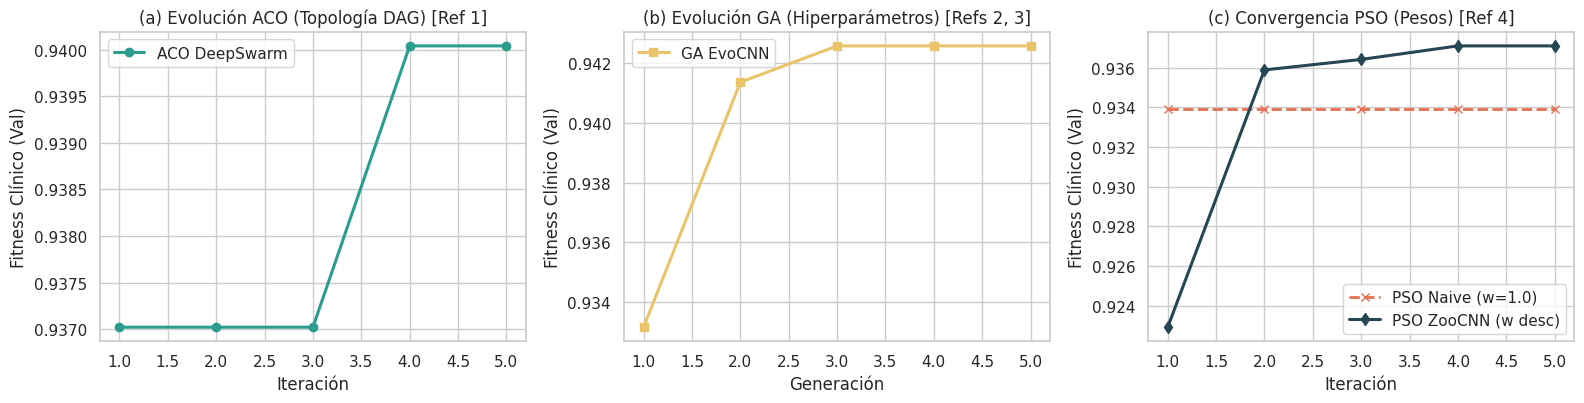

In [ ]:
# ==============================================================================
# 2. GRÁFICA: EVOLUCIÓN Y CONVERGENCIA DE TODAS LAS METAHEURÍSTICAS (ACO, GA, PSO)
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

# (a) ACO
axes[0].plot(range(1, len(curva_aco)+1), curva_aco, marker='o', lw=2.2, color='#2a9d8f', label='ACO DeepSwarm')
axes[0].set_title('(a) Evolución ACO (Topología DAG) [Ref 1]')
axes[0].set_xlabel('Iteración'); axes[0].set_ylabel('Fitness Clínico (Val)'); axes[0].legend()

# (b) GA
axes[1].plot(range(1, len(curva_ga)+1), curva_ga, marker='s', lw=2.2, color='#e9c46a', label='GA EvoCNN')
axes[1].set_title('(b) Evolución GA (Hiperparámetros) [Refs 2, 3]')
axes[1].set_xlabel('Generación'); axes[1].set_ylabel('Fitness Clínico (Val)'); axes[1].legend()

# (c) PSO (Naive vs ZooCNN)
if curva_pso_naive is not None and curva_pso_zoocnn is not None:
    axes[2].plot(range(1, len(curva_pso_naive)+1), curva_pso_naive, marker='x', ls='--', lw=2.0, color='#e76f51', label='PSO Naive (w=1.0)')
    axes[2].plot(range(1, len(curva_pso_zoocnn)+1), curva_pso_zoocnn, marker='d', lw=2.2, color='#264653', label='PSO ZooCNN (w desc)')
    axes[2].set_title('(c) Convergencia PSO (Pesos) [Ref 4]')
    axes[2].set_xlabel('Iteración'); axes[2].set_ylabel('Fitness Clínico (Val)'); axes[2].legend()
else:
    axes[2].text(0.5, 0.5, 'Curvas PSO no disponibles aún', ha='center', va='center')
    axes[2].set_title('(c) Convergencia PSO [Ref 4]')

plt.tight_layout()
guardar('B1_convergencia_algoritmos')

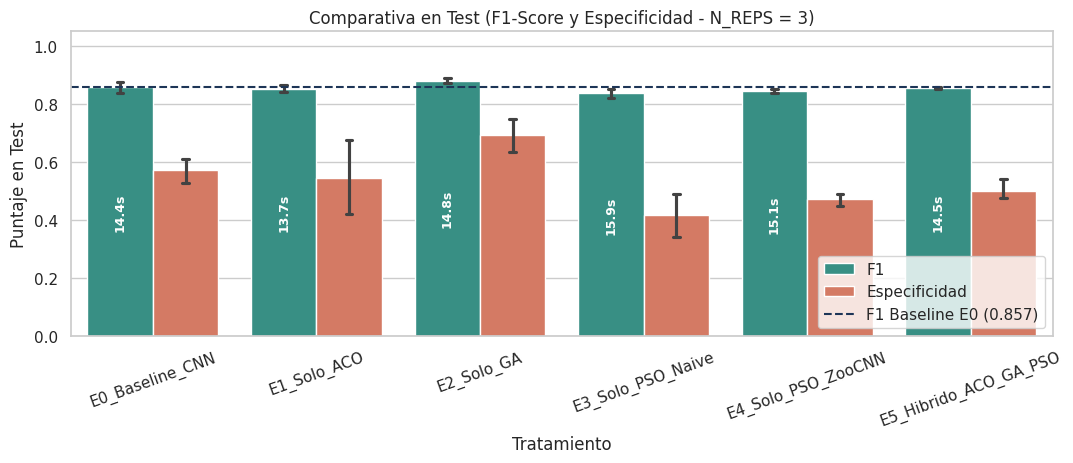

In [ ]:
# ==============================================================================
# 3. GRÁFICA: BARRAS COMPARATIVAS DE MÉTRICAS Y TIEMPOS DE EJECUCIÓN
# ==============================================================================
df_melt = df_protocolo.melt(
    id_vars=['Tratamiento', 'Repeticion'],
    value_vars=['F1', 'Especificidad'],
    var_name='Metrica', value_name='Valor'
)

plt.figure(figsize=(11, 4.8))
ax = sns.barplot(data=df_melt, x='Tratamiento', y='Valor', hue='Metrica', palette=['#2a9d8f', '#e76f51'], capsize=.08)
plt.axhline(f1_baseline_mean, ls='--', color='#1d3557', lw=1.5, label=f'F1 Baseline E0 ({f1_baseline_mean:.3f})')
plt.title('Comparativa en Test (F1-Score y Especificidad - N_REPS = 3)')
plt.xticks(rotation=20); plt.ylim(0.0, 1.05); plt.ylabel('Puntaje en Test')

# Añadir etiquetas de tiempo promedio sobre las barras
tiempos_medios = df_protocolo.groupby('Tratamiento')['Tiempo_s'].mean().values
for idx, p in enumerate(ax.patches[:len(tiempos_medios)]):
    h = p.get_height()
    if h > 0:
        ax.annotate(f"{tiempos_medios[idx]:.1f}s", (p.get_x() + p.get_width() / 2., h / 2),
                    ha='center', va='center', fontsize=9, color='white', weight='bold', rotation=90)

plt.legend(loc='lower right')
plt.tight_layout()
guardar('B2_comparativa_metricas_protocolo')

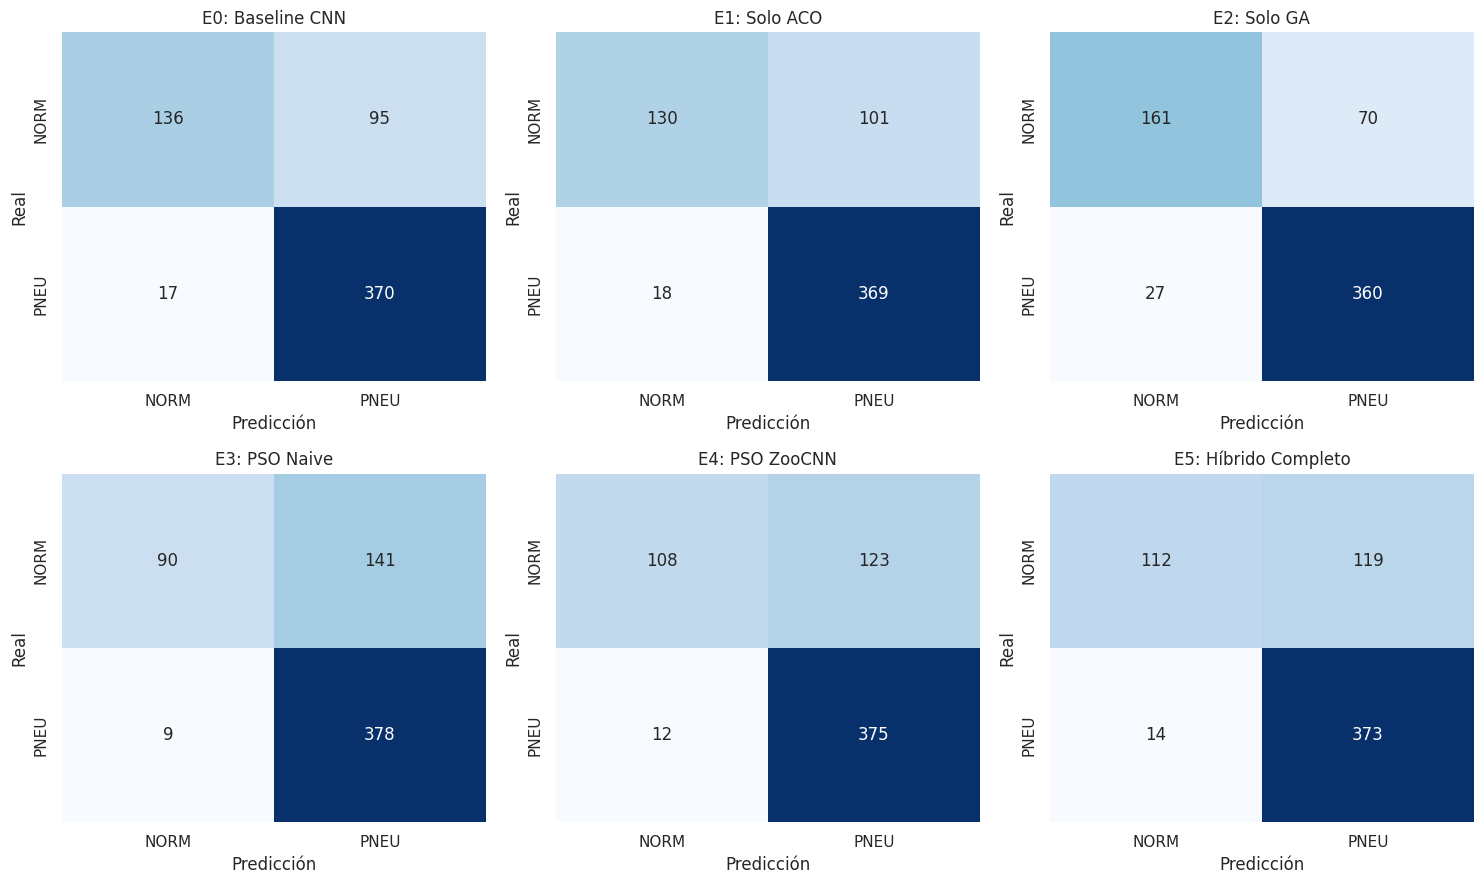

In [ ]:
# ==============================================================================
# 4. GRÁFICA: MATRICES DE CONFUSIÓN PARA LOS 6 TRATAMIENTOS (E0 A E5)
# ==============================================================================
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()

trats_completos = [
    ('E0_Baseline_CNN', 'E0: Baseline CNN'),
    ('E1_Solo_ACO', 'E1: Solo ACO'),
    ('E2_Solo_GA', 'E2: Solo GA'),
    ('E3_Solo_PSO_Naive', 'E3: PSO Naive'),
    ('E4_Solo_PSO_ZooCNN', 'E4: PSO ZooCNN'),
    ('E5_Hibrido_ACO_GA_PSO', 'E5: Híbrido Completo')
]

for idx, (clave, titulo) in enumerate(trats_completos):
    preds = (probabilidades_test[clave] >= 0.5).astype(int)
    cm = confusion_matrix(yte, preds, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[idx],
                xticklabels=['NORM', 'PNEU'], yticklabels=['NORM', 'PNEU'])
    axes[idx].set_title(titulo)
    axes[idx].set_xlabel('Predicción')
    axes[idx].set_ylabel('Real')

plt.tight_layout()
guardar('B3_matrices_confusion_todos')

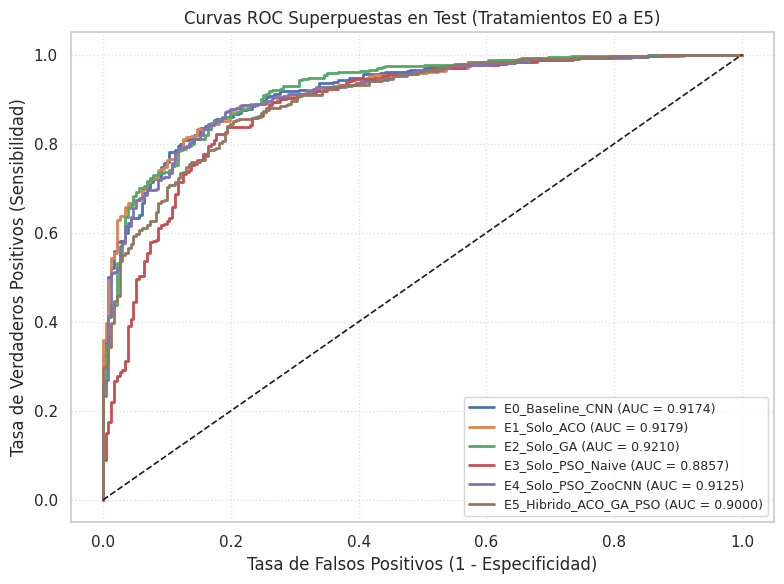

In [ ]:
# ==============================================================================
# 5. GRÁFICA: CURVAS ROC SUPERPUESTAS (E0 A E5)
# ==============================================================================
plt.figure(figsize=(8, 6))

for nombre, _, _, _ in tratamientos:
    probs_t = probabilidades_test[nombre]
    fpr, tpr, _ = roc_curve(yte, probs_t)
    auc_t = roc_auc_score(yte, probs_t)
    plt.plot(fpr, tpr, lw=2.0, label=f"{nombre} (AUC = {auc_t:.4f})")

plt.plot([0, 1], [0, 1], 'k--', lw=1.2)
plt.title('Curvas ROC Superpuestas en Test (Tratamientos E0 a E5)')
plt.xlabel('Tasa de Falsos Positivos (1 - Especificidad)')
plt.ylabel('Tasa de Verdaderos Positivos (Sensibilidad)')
plt.legend(fontsize=9, loc='lower right')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
guardar('B4_curvas_roc_superpuestas')

## Marco Bibliográfico y Justificación de Modificaciones Algorítmicas

Para el desarrollo de esta fase, la literatura científica no se emplea para justificar la elección teórica de los algoritmos (ACO, GA y PSO), sino para fundamentar **qué ecuaciones, operadores, restricciones paramétricas y decisiones de implementación específicas** se programaron en el código, adaptándolas al problema de clasificación de neumonía en imágenes de rayos X de tórax:

1. **Algoritmo ACO (Colonia de Hormigas) – Capas de Convolución y Pooling:**
   * **Referencia [1]:** Byla, E., & Pang, W. (2019). *DeepSwarm: Optimising Convolutional Neural Networks using Swarm Intelligence*. En *Advances in Computational Intelligence Systems (UKCI 2019)* (pp. 119–130). Springer.
   * **Cómo se usó en el código:** Se modeló la estructura de la CNN como un grafo dirigido acíclico (DAG) donde las hormigas exploran combinaciones de filtros, tamaños de kernel y reducción espacial. Se aplicaron los tres mecanismos de *Ant Colony System (ACS)* descritos por Byla & Pang[cite: 1]: la regla de selección pseudo-aleatoria con factor de avaricia ($q_0 = 0.50$), la heurística local $\eta$ (favoreciendo kernels $3\times 3$ frente a $5\times 5$), y el **desgaste local de feromona ($\xi = 0.10$)** aplicado inmediatamente tras el paso de cada hormiga para forzar la exploración de rutas alternativas bajo el límite de épocas cortas.

2. **Algoritmo Genético (GA) – Hiperparámetros e Inicialización Estadística:**
   * **Referencia [2]:** Sun, Y., Xue, B., Zhang, M., & Yen, G. G. (2020). *Evolving Deep Convolutional Neural Networks for Image Classification*. *IEEE Transactions on Evolutionary Computation*, 24(2), 394–407.
   * **Referencia [3]:** Nwohiri, A., Olukolatimi, D., & Alase, A. (2026). *Systematic Hyperparameter Optimization of Convolutional Neural Networks for Pneumonia Detection from Chest X-rays*. *Periodica Polytechnica Electrical Engineering and Computer Science*, 70(1), 78–88.
   * **Cómo se usó en el código:** De acuerdo con *EvoCNN*[cite: 2], el cromosoma no optimiza miles de pesos individuales, sino que codifica la media ($\mu$) y la desviación estándar ($\sigma$) del inicializador gaussiano de las capas. Asimismo, implementamos la **Selección por Torneo con Holgura ($\epsilon = 0.01$)**[cite: 2] para priorizar redes menos complejas ante desempeños equivalentes. Por otro lado, basándonos en el análisis de sensibilidad en rayos X de Nwohiri et al.[cite: 3], acotamos matemáticamente el gen de `dropout` al intervalo estricto $[0.15, 0.40]$ para evitar el colapso de características pulmonares sutiles.

3. **Algoritmo PSO (Enjambre de Partículas) – Optimización de Pesos:**
   * **Referencia [4]:** Ganesan, S. K., Velusamy, P., Rajendran, S., Sakthivel, R., Bose, M., & Inbaraj, B. S. (2025). *ZooCNN: A Zero-Order Optimized Convolutional Neural Network for Pneumonia Classification Using Chest Radiographs*. *Journal of Imaging (MDPI)*, 11(1), 22.
   * **Cómo se usó en el código:** Siguiendo la arquitectura de *ZooCNN* para evitar la divergencia por alta dimensionalidad, restringimos la optimización de orden cero al subespacio reducido de la capa densa de salida (post-extracción). Programamos un contraste directo en el protocolo:
     * **Modo `naive`:** Inicialización de partículas aleatoria en $[-1.5, 1.5]$ sin *Warm-Start*, con inercia alta fija ($w = 1.0$), demostrando cómo la optimización libre de gradiente sin control **perjudica** drásticamente al modelo.
     * **Modo `zoocnn_pso`:** Incorpora *Warm-Start* a partir de los pesos de Adam, **inercia linealmente decreciente ($w: 0.9 \to 0.4$)**, coeficientes $c_1 = c_2 = 1.5$ y acotamiento de velocidad ($V_{\max} = 0.10$), demostrando cómo esta modificación bibliográfica estabiliza el enjambre y **beneficia** el rendimiento.
   * **Fitness Clínico Compuesto:** Para mitigar el desbalance entre clases de rayos X, la función objetivo se programó combinando $0.50 \cdot \text{F1} + 0.25 \cdot \text{Sensibilidad} + 0.25 \cdot \text{Especificidad}$.